In [2]:
import numpy as np
import pandas as pd

from sklearn.metrics import classification_report, root_mean_squared_error, mean_squared_error, mean_absolute_error, r2_score, roc_auc_score, f1_score, accuracy_score
import sklearn.model_selection as ms
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler


from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn import neighbors 

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, AdaBoostClassifier, AdaBoostRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from xgboost import XGBClassifier

In [3]:
df = pd.read_csv('robot_instability_dataset.csv')

In [4]:
y = df["instability_index"]
y_binary = (y > 1).astype(int)
groups = df["environment"] + "_" + (df.groupby("environment").cumcount() // 500).astype(str)
X_clean = pd.get_dummies(df.drop(columns=["instability_index"]))

#Split by time instead of by datapoints since we are dealing with time-series data
splitter = ms.StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=21)
train_idx, test_idx = next(splitter.split(X_clean, y_binary, groups))

X_train, X_test = X_clean.iloc[train_idx], X_clean.iloc[test_idx]
y_train, y_test = y_binary.iloc[train_idx], y_binary.iloc[test_idx]
groups_train = groups.iloc[train_idx]

scaler = StandardScaler()
X_scaled_train = scaler.fit_transform(X_train)
X_scaled_test = scaler.transform(X_test)

group_cv = list(ms.StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=21).split(X_train, y_train, groups_train))

In [5]:
log_model = LogisticRegression(penalty=None)
log_model.fit(X_train, y_train)

y_pred = log_model.predict(X_test)
y_pred_probability = log_model.predict_proba(X_test)[:, 1]

log_auc = roc_auc_score(y_test, y_pred_probability)
log_f1 = f1_score(y_test, y_pred)
log_acc = accuracy_score(y_test, y_pred)

print("The AUC of the Logistic Regression of the model is:", log_auc)
print("The F1 of the Logistic Regression of the model is:", log_f1)
print("The Accuracy of the Logistic Regression of the model is:", log_acc)

The AUC of the Logistic Regression of the model is: 0.8095472563017497
The F1 of the Logistic Regression of the model is: 0.0
The Accuracy of the Logistic Regression of the model is: 0.9858749186878543


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [6]:
alphas = np.logspace(-3, 5, 200)

ridge_model = LogisticRegressionCV(Cs=alphas, cv=group_cv, scoring="average_precision", class_weight="balanced")
ridge_model.fit(X_scaled_train, y_train)

y_pred = ridge_model.predict(X_scaled_test)
y_pred_probability = ridge_model.predict_proba(X_scaled_test)[:, 1]

ridge_auc = roc_auc_score(y_test, y_pred_probability)
ridge_f1 = f1_score(y_test, y_pred)
ridge_acc = accuracy_score(y_test, y_pred)

print(f"Optimal Alpha (Penalty): {ridge_model.C_[0]}")
print("The AUC of the Ridge Logistic Regression of the model is:", ridge_auc)
print("The F1 of the Ridge Logistic Regression of the model is:", ridge_f1)
print("The Accuracy of the Ridge Logistic Regression of the model is:", ridge_acc)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2092: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2150: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details

Optimal Alpha (Penalty): 0.14820207057988585
The AUC of the Ridge Logistic Regression of the model is: 0.8148989686016341
The F1 of the Ridge Logistic Regression of the model is: 0.07612903225806451
The Accuracy of the Ridge Logistic Regression of the model is: 0.733853731065886


In [7]:
k_neighbors = list(range(1,21,2))   
n_grid = [{'n_neighbors': k_neighbors}]

model = neighbors.KNeighborsClassifier()

cv_knn = ms.GridSearchCV(estimator=model, param_grid=n_grid, cv=group_cv, scoring="average_precision")
cv_knn.fit(X_scaled_train, y_train)

#best_k = cv_knn.best_params_['n_neighbors']

y_pred = cv_knn.predict(X_scaled_test)
y_pred_probability = cv_knn.predict_proba(X_scaled_test)[:, 1]

knn_auc = roc_auc_score(y_test, y_pred_probability)
knn_f1 = f1_score(y_test, y_pred)
knn_acc = accuracy_score(y_test, y_pred)

print("The AUC of the KNN of the model is:", knn_auc)
print("The F1 of the KNN of the model is:", knn_f1)
print("The Accuracy of the KNN of the model is:", knn_acc)

The AUC of the KNN of the model is: 0.7366411835035794
The F1 of the KNN of the model is: 0.0
The Accuracy of the KNN of the model is: 0.9855961341882724


In [8]:
depth_val = np.arange(2,10)
leaf_val = np.arange(1,31,10)

grid_s = [{'max_depth': depth_val,'min_samples_leaf': leaf_val}]

cv_forest = ms.GridSearchCV(RandomForestClassifier(random_state = 21, class_weight="balanced_subsample"), param_grid=grid_s, cv=group_cv, scoring="average_precision")
cv_forest.fit(X_train, y_train)

y_pred = cv_forest.predict(X_test)
y_pred_probability = cv_forest.predict_proba(X_test)[:, 1]

randomforest_auc = roc_auc_score(y_test, y_pred_probability)
randomforest_f1 = f1_score(y_test, y_pred)
randomforest_acc = accuracy_score(y_test, y_pred)

print("The AUC of the Random Forest of the model is:", randomforest_auc)
print("The F1 of the Random Forest of the model is:", randomforest_f1)
print("The Accuracy of the Random Forest of the model is:", randomforest_acc)

The AUC of the Random Forest of the model is: 0.8430357665537205
The F1 of the Random Forest of the model is: 0.08828382838283828
The Accuracy of the Random Forest of the model is: 0.7946287519747235


In [9]:
depth_val = np.arange(1,10)
leaf_val = np.arange(1,31,10)

grid_s = [{'estimator__max_depth': depth_val,'estimator__min_samples_leaf': leaf_val}]
cv_forest = ms.GridSearchCV(AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=21, class_weight="balanced"), random_state=21), param_grid=grid_s, cv=group_cv, scoring="average_precision")
cv_forest.fit(X_train, y_train)

y_pred = cv_forest.predict(X_test)
y_pred_probability = cv_forest.predict_proba(X_test)[:, 1]

adaboost_auc = roc_auc_score(y_test, y_pred_probability)
adaboost_f1 = f1_score(y_test, y_pred)
adaboost_acc = accuracy_score(y_test, y_pred)

print("The AUC of the Adaboost of the model is:", adaboost_auc)
print("The F1 of the Adaboost of the model is:", adaboost_f1)
print("The Accuracy of the Adaboost of the model is:", adaboost_acc)

The AUC of the Adaboost of the model is: 0.8055781213567428
The F1 of the Adaboost of the model is: 0.0842358604091456
The Accuracy of the Adaboost of the model is: 0.7878449958182325


In [10]:
xgboost_model = XGBClassifier(objective="binary:logistic", n_estimators=100, max_depth=5, learning_rate=0.1, tree_method="hist", enable_categorical=True, random_state=42, scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum())
xgboost_model.fit(X_train, y_train)

y_pred = xgboost_model.predict(X_test)
y_pred_probability = xgboost_model.predict_proba(X_test)[:, 1]

xgboost_auc = roc_auc_score(y_test, y_pred_probability)
xgboost_f1 = f1_score(y_test, y_pred)
xgboost_acc = accuracy_score(y_test, y_pred)

print("The AUC of the XGBoost of the model is:", xgboost_auc)
print("The F1 of the XGBoost of the model is:", xgboost_f1)
print("The Accuracy of the XGBoost of the model is:", xgboost_acc)


The AUC of the XGBoost of the model is: 0.8108851843767207
The F1 of the XGBoost of the model is: 0.08702791461412152
The Accuracy of the XGBoost of the model is: 0.7933277576433417


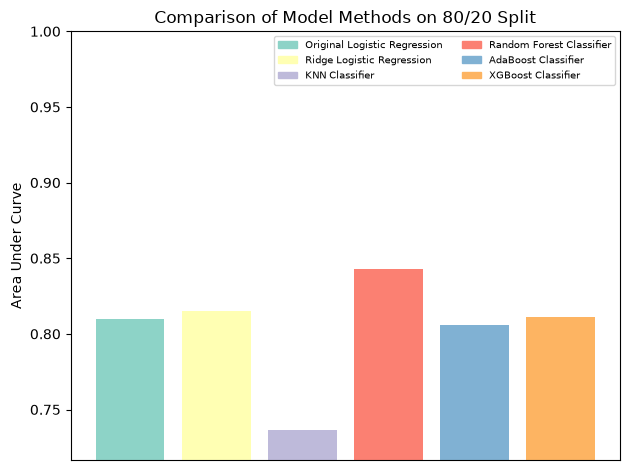

In [13]:
import matplotlib.pyplot as plt

df = pd.DataFrame(
    {'Model': ['Original Logistic Regression', 'Ridge Logistic Regression', 'KNN Classifier', 'Random Forest Classifier', 'AdaBoost Classifier', 'XGBoost Classifier'],
    'AUC': [log_auc, ridge_auc, knn_auc, randomforest_auc, adaboost_auc, xgboost_auc]
})

models = {'Original Logistic Regression':'#8dd3c7', 'Ridge Logistic Regression':'#ffffb3', 'KNN Classifier':'#bebada', 'Random Forest Classifier':'#fb8072', 'AdaBoost Classifier':'#80b1d3', 'XGBoost Classifier': '#fdb462'}         
labels = list(models.keys())
handles = [plt.Rectangle((0,0),1,1, color=models[label]) for label in labels]
bars = plt.bar(df['Model'], df['AUC'], color = ['#8dd3c7', '#ffffb3', '#bebada', '#fb8072', '#80b1d3', '#fdb462'], label=False)
plt.legend(handles, labels, fontsize=7, ncol=2, loc='upper right')   
plt.xticks([])
plt.ylabel('Area Under Curve')
plt.title('Comparison of Model Methods on 80/20 Split')
plt.ylim(min(df['AUC']) - 0.02, 1.0)
plt.tight_layout()

plt.savefig("./images/binary_model_output.png", dpi=300, bbox_inches='tight')